# Implementasi Fuzzy Inference System (FIS) – Smart City Multi-Zone Load Forecasting

**Fokus:** pengembangan dan pengujian Fuzzy Inference System secara mandiri. Notebook ini tidak mengubah model RNN, Genetic Algorithm, maupun dashboard anggota kelompok lain.

## Tujuan
1. Mengambil dataset Tetouan City Power Consumption (UCI ID 849).
2. Menentukan rentang fungsi keanggotaan berdasarkan data training.
3. Membangun FIS Mamdani dengan dua input dan satu output.
4. Menguji kelengkapan aturan dan beberapa skenario.
5. Menyimpan grafik serta tabel hasil pengujian.

**Catatan metodologis:** FIS pada notebook ini mengklasifikasikan tingkat beban berdasarkan total beban dan temperatur. Skor FIS bukan metrik akurasi model prediksi dan tidak membuktikan peningkatan MAE/RMSE/R² RNN.

## 1. Persiapan pustaka

In [ ]:
!pip -q install ucimlrepo scikit-fuzzy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from IPython.display import display

## 2. Mengambil dan menyiapkan dataset

In [ ]:
from ucimlrepo import fetch_ucirepo

# Dataset Tetouan City Power Consumption (UCI Machine Learning Repository, ID 849)
dataset = fetch_ucirepo(id=849)
df = dataset.data.original.copy()

# Rapikan nama kolom dan temukan kolom yang diperlukan
df.columns = df.columns.astype(str).str.strip().str.replace(r'\\s+', ' ', regex=True)

def cari_kolom(kata):
    hasil = [c for c in df.columns if kata.lower() in c.lower()]
    if not hasil:
        raise KeyError(f"Kolom dengan kata '{kata}' tidak ditemukan. Kolom tersedia: {df.columns.tolist()}")
    return hasil[0]

kolom_waktu = cari_kolom('datetime')
kolom_suhu = cari_kolom('temperature')
kolom_zona = [cari_kolom('zone 1'), cari_kolom('zone 2'), cari_kolom('zone 3')]

df[kolom_waktu] = pd.to_datetime(df[kolom_waktu], errors='coerce')
for c in kolom_zona + [kolom_suhu]:
    df[c] = pd.to_numeric(df[c], errors='coerce')

df = (df.dropna(subset=[kolom_waktu] + kolom_zona + [kolom_suhu])
        .sort_values(kolom_waktu)
        .reset_index(drop=True))

df['Total_Beban'] = df[kolom_zona].sum(axis=1)

print("Jumlah data setelah pembersihan:", len(df))
print("Kolom zona:", kolom_zona)
print("Kolom temperatur:", kolom_suhu)
display(df[[kolom_waktu] + kolom_zona + [kolom_suhu, 'Total_Beban']].head())

Jumlah data setelah pembersihan: 52416
Kolom zona: ['Zone 1 Power Consumption', 'Zone 2  Power Consumption', 'Zone 3  Power Consumption']
Kolom temperatur: Temperature


,DateTime,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption,Temperature,Total_Beban
0,2017-01-01 00:00:00,34055.69620,16128.87538,20240.96386,6.559,70425.53544
1,2017-01-01 00:10:00,29814.68354,19375.07599,20131.08434,6.414,69320.84387
2,2017-01-01 00:20:00,29128.10127,19006.68693,19668.43373,6.313,67803.22193
3,2017-01-01 00:30:00,28228.86076,18361.09422,18899.27711,6.121,65489.23209
4,2017-01-01 00:40:00,27335.69620,17872.34043,18442.40964,5.921,63650.44627


## 3. Menentukan parameter fungsi keanggotaan

Data dibagi secara kronologis: 70% bagian awal digunakan sebagai data training untuk memperoleh parameter fungsi keanggotaan. Pembagian kronologis dipilih agar urutan waktu tidak tercampur.

Persentil ke-10, 50, dan 90 (P10, P50, P90) digunakan sebagai titik acuan himpunan Rendah/Sejuk, Sedang, dan Tinggi/Panas. Nilai minimum dan maksimum training menjadi batas domain.

In [ ]:
batas_train = int(len(df) * 0.70)
train = df.iloc[:batas_train].copy()

def ringkasan_parameter(data, kolom):
    q = data[kolom].quantile([0.10, 0.50, 0.90])
    return {
        'min': float(data[kolom].min()),
        'P10': float(q.loc[0.10]),
        'P50': float(q.loc[0.50]),
        'P90': float(q.loc[0.90]),
        'max': float(data[kolom].max())
    }

param_beban = ringkasan_parameter(train, 'Total_Beban')
param_suhu = ringkasan_parameter(train, kolom_suhu)

tabel_parameter = pd.DataFrame(
    [param_beban, param_suhu],
    index=['Total beban', 'Temperatur']
).round(3)

print(f"Data training: {len(train)} dari {len(df)} baris ({len(train)/len(df):.1%})")
display(tabel_parameter)

# Pastikan urutan titik pembentuk fungsi keanggotaan valid
for nama, p in [('beban', param_beban), ('temperatur', param_suhu)]:
    if not (p['min'] < p['P10'] < p['P50'] < p['P90'] < p['max']):
        raise ValueError(
            f"Urutan parameter {nama} tidak memenuhi min < P10 < P50 < P90 < max. "
            "Periksa distribusi data sebelum membangun FIS."
        )

Data training: 36691 dari 52416 baris (70.0%)


,min,P10,P50,P90,max
Total beban,37436.223,50614.769,71642.211,96995.992,134208.146
Temperatur,3.247,11.410,19.160,27.230,40.010


## 4. Membangun variabel fuzzy dan fungsi keanggotaan

- Input 1: **Total Beban** (penjumlahan beban Zona 1, Zona 2, dan Zona 3).
- Input 2: **Temperatur** (°C).
- Output: **Skor Tingkat Beban** pada rentang 0–100.

Fungsi keanggotaan input menggunakan trapezoid untuk kategori tepi dan segitiga untuk kategori tengah. Output menggunakan empat himpunan: Very Low, Normal, High, dan Critical Peak.

In [ ]:
# Domain input mengikuti rentang data training dengan batas aktual min dan max.
# Penambahan titik-titik rapat membuat proses inferensi lebih halus.
total = ctrl.Antecedent(
    np.linspace(param_beban['min'], param_beban['max'], 1001),
    'Total Beban'
)
suhu = ctrl.Antecedent(
    np.linspace(param_suhu['min'], param_suhu['max'], 801),
    'Temperatur'
)
tingkat = ctrl.Consequent(np.arange(0, 100.1, 0.5), 'Skor Tingkat Beban')

# Fungsi keanggotaan total beban
total['Rendah'] = fuzz.trapmf(
    total.universe,
    [param_beban['min'], param_beban['min'], param_beban['P10'], param_beban['P50']]
)
total['Sedang'] = fuzz.trimf(
    total.universe,
    [param_beban['P10'], param_beban['P50'], param_beban['P90']]
)
total['Tinggi'] = fuzz.trapmf(
    total.universe,
    [param_beban['P50'], param_beban['P90'], param_beban['max'], param_beban['max']]
)

# Fungsi keanggotaan temperatur
suhu['Sejuk'] = fuzz.trapmf(
    suhu.universe,
    [param_suhu['min'], param_suhu['min'], param_suhu['P10'], param_suhu['P50']]
)
suhu['Sedang'] = fuzz.trimf(
    suhu.universe,
    [param_suhu['P10'], param_suhu['P50'], param_suhu['P90']]
)
suhu['Panas'] = fuzz.trapmf(
    suhu.universe,
    [param_suhu['P50'], param_suhu['P90'], param_suhu['max'], param_suhu['max']]
)

# Fungsi keanggotaan output (skala 0-100)
tingkat['Very Low'] = fuzz.trapmf(tingkat.universe, [0, 0, 10, 30])
tingkat['Normal'] = fuzz.trimf(tingkat.universe, [20, 40, 60])
tingkat['High'] = fuzz.trimf(tingkat.universe, [50, 70, 90])
tingkat['Critical Peak'] = fuzz.trapmf(tingkat.universe, [75, 90, 100, 100])

print("Variabel fuzzy berhasil dibentuk.")

Variabel fuzzy berhasil dibentuk.


## 5. Visualisasi fungsi keanggotaan

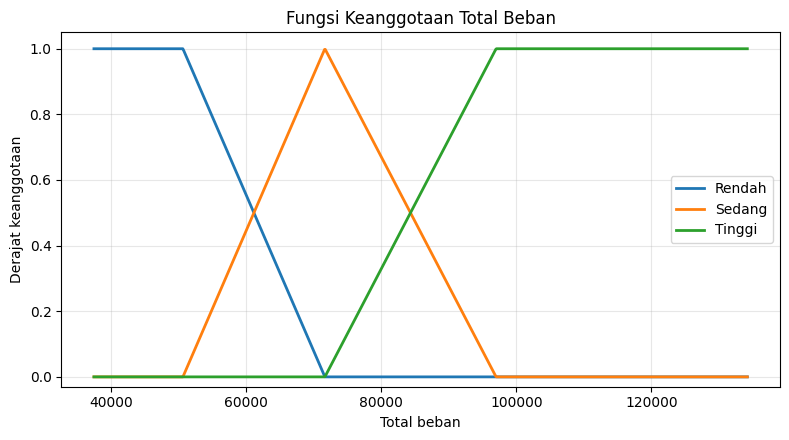

Grafik tersimpan: FIS_membership_total_beban.png


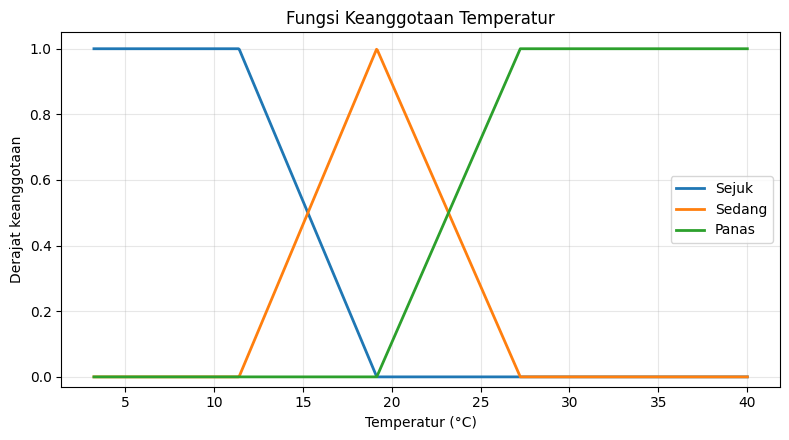

Grafik tersimpan: FIS_membership_temperatur.png


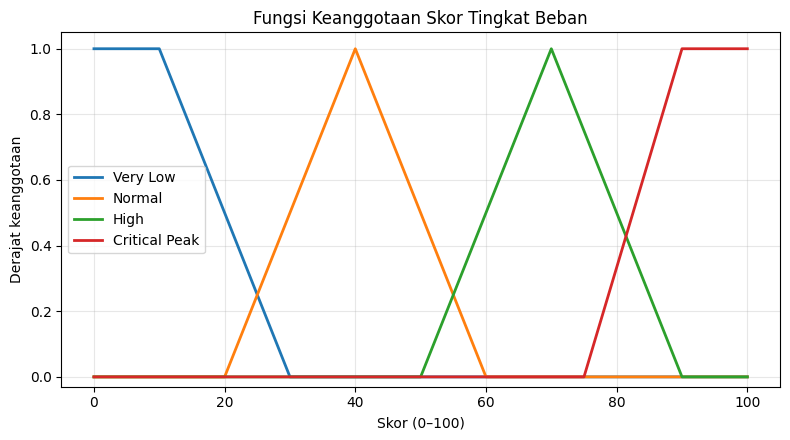

Grafik tersimpan: FIS_membership_output.png


In [ ]:
def plot_membership(variabel, judul, label_x, nama_file):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for nama, term in variabel.terms.items():
        ax.plot(variabel.universe, term.mf, linewidth=2, label=nama)
    ax.set_title(judul)
    ax.set_xlabel(label_x)
    ax.set_ylabel('Derajat keanggotaan')
    ax.set_ylim(-0.03, 1.05)
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(nama_file, dpi=200, bbox_inches='tight')
    plt.show()
    print('Grafik tersimpan:', nama_file)

plot_membership(total, 'Fungsi Keanggotaan Total Beban', 'Total beban', 'FIS_membership_total_beban.png')
plot_membership(suhu, 'Fungsi Keanggotaan Temperatur', 'Temperatur (°C)', 'FIS_membership_temperatur.png')
plot_membership(tingkat, 'Fungsi Keanggotaan Skor Tingkat Beban', 'Skor (0–100)', 'FIS_membership_output.png')

## 6. Menyusun basis aturan (rule base)

Basis aturan terdiri dari 9 kombinasi input (3 kategori total beban × 3 kategori temperatur). Operator AND menggunakan metode minimum, agregasi menggunakan maksimum, dan defuzzifikasi menggunakan centroid (pusat luas).

| Total Beban | Sejuk | Sedang | Panas |
|---|---|---|---|
| Rendah | Very Low | Very Low | Normal |
| Sedang | Normal | Normal | High |
| Tinggi | High | High | Critical Peak |

In [ ]:
rules = [
    ctrl.Rule(total['Rendah'] & suhu['Sejuk'], tingkat['Very Low']),
    ctrl.Rule(total['Rendah'] & suhu['Sedang'], tingkat['Very Low']),
    ctrl.Rule(total['Rendah'] & suhu['Panas'], tingkat['Normal']),
    ctrl.Rule(total['Sedang'] & suhu['Sejuk'], tingkat['Normal']),
    ctrl.Rule(total['Sedang'] & suhu['Sedang'], tingkat['Normal']),
    ctrl.Rule(total['Sedang'] & suhu['Panas'], tingkat['High']),
    ctrl.Rule(total['Tinggi'] & suhu['Sejuk'], tingkat['High']),
    ctrl.Rule(total['Tinggi'] & suhu['Sedang'], tingkat['High']),
    ctrl.Rule(total['Tinggi'] & suhu['Panas'], tingkat['Critical Peak']),
]

sistem_fis = ctrl.ControlSystem(rules)
print('Jumlah aturan:', len(rules))
assert len(rules) == 9, 'Jumlah aturan tidak sesuai kombinasi 3 x 3.'
print('Validasi jumlah aturan: LULUS (9 dari 9 kombinasi).')

Jumlah aturan: 9
Validasi jumlah aturan: LULUS (9 dari 9 kombinasi).


## 7. Fungsi inferensi dan klasifikasi

Fungsi berikut menerima nilai total beban dan temperatur, menjalankan inferensi Mamdani, lalu mengubah skor crisp menjadi kategori. Nilai input di luar domain training ditolak agar hasil ekstrapolasi tidak disajikan seolah-olah valid.

In [ ]:
def klasifikasi_fuzzy(nilai_beban, nilai_suhu):
    nilai_beban = float(nilai_beban)
    nilai_suhu = float(nilai_suhu)

    if not np.isfinite(nilai_beban) or not np.isfinite(nilai_suhu):
        raise ValueError('Input harus berupa angka yang valid.')
    if not (param_beban['min'] <= nilai_beban <= param_beban['max']):
        raise ValueError(
            f'Total beban {nilai_beban:.3f} di luar domain training '
            f'[{param_beban["min"]:.3f}, {param_beban["max"]:.3f}].'
        )
    if not (param_suhu['min'] <= nilai_suhu <= param_suhu['max']):
        raise ValueError(
            f'Temperatur {nilai_suhu:.3f} di luar domain training '
            f'[{param_suhu["min"]:.3f}, {param_suhu["max"]:.3f}].'
        )

    simulasi = ctrl.ControlSystemSimulation(sistem_fis)
    simulasi.input['Total Beban'] = nilai_beban
    simulasi.input['Temperatur'] = nilai_suhu
    simulasi.compute()

    skor = float(simulasi.output['Skor Tingkat Beban'])
    if skor < 25:
        kategori = 'Very Low'
    elif skor < 55:
        kategori = 'Normal'
    elif skor < 80:
        kategori = 'High'
    else:
        kategori = 'Critical Peak'

    return round(skor, 2), kategori

print('Fungsi klasifikasi fuzzy siap digunakan.')

Fungsi klasifikasi fuzzy siap digunakan.


## 8. Pengujian skenario

Skenario dibentuk dari persentil data training agar seluruh input berada pada domain yang telah ditentukan. Pengujian ini merupakan **uji fungsi berbasis skenario**, bukan evaluasi performa prediksi RNN dan bukan pengujian seluruh data uji.

In [ ]:
# Delapan skenario dengan kombinasi kondisi beban dan temperatur.
skenario = [
    ('Beban rendah - suhu sejuk', param_beban['P10'], param_suhu['P10']),
    ('Beban rendah - suhu sedang', param_beban['P10'], param_suhu['P50']),
    ('Beban rendah - suhu panas', param_beban['P10'], param_suhu['P90']),
    ('Beban sedang - suhu sejuk', param_beban['P50'], param_suhu['P10']),
    ('Beban sedang - suhu sedang', param_beban['P50'], param_suhu['P50']),
    ('Beban sedang - suhu panas', param_beban['P50'], param_suhu['P90']),
    ('Beban tinggi - suhu sejuk', param_beban['P90'], param_suhu['P10']),
    ('Beban tinggi - suhu panas', param_beban['P90'], param_suhu['P90']),
]

hasil_skenario = []
for nama, b, t in skenario:
    skor, kategori = klasifikasi_fuzzy(b, t)
    hasil_skenario.append({
        'Skenario': nama,
        'Total Beban': round(b, 2),
        'Temperatur (°C)': round(t, 2),
        'Skor FIS': skor,
        'Kategori': kategori
    })

df_hasil_skenario = pd.DataFrame(hasil_skenario)
display(df_hasil_skenario)

,Skenario,Total Beban,Temperatur (°C),Skor FIS,Kategori
0,Beban rendah - suhu sejuk,50614.77,11.41,10.87,Very Low
1,Beban rendah - suhu sedang,50614.77,19.16,10.97,Very Low
2,Beban rendah - suhu panas,50614.77,27.23,40.02,Normal
3,Beban sedang - suhu sejuk,71642.21,11.41,40.02,Normal
4,Beban sedang - suhu sedang,71642.21,19.16,40.05,Normal
5,Beban sedang - suhu panas,71642.21,27.23,69.92,High
6,Beban tinggi - suhu sejuk,96995.99,11.41,69.95,High
7,Beban tinggi - suhu panas,96995.99,27.23,90.62,Critical Peak


## 9. Pemeriksaan tambahan dan ekspor hasil

In [ ]:
# Pemeriksaan nilai output dan kelengkapan hasil skenario
assert len(df_hasil_skenario) == len(skenario)
assert df_hasil_skenario['Skor FIS'].between(0, 100).all()
assert df_hasil_skenario['Kategori'].notna().all()

print('Jumlah skenario diuji:', len(df_hasil_skenario))
print('Skor minimum hasil uji:', df_hasil_skenario['Skor FIS'].min())
print('Skor maksimum hasil uji:', df_hasil_skenario['Skor FIS'].max())
print('Pemeriksaan output: LULUS')

df_hasil_skenario.to_csv('hasil_pengujian_skenario_FIS.csv', index=False)
tabel_parameter.to_csv('parameter_membership_FIS.csv')
print('File CSV berhasil disimpan.')

Jumlah skenario diuji: 8
Skor minimum hasil uji: 10.87
Skor maksimum hasil uji: 90.62
Pemeriksaan output: LULUS
File CSV berhasil disimpan.


### 9.1 Visualisasi Hasil Pengujian Skenario

Untuk mempermudah analisis hasil dari Fuzzy Inference System (FIS), berikut adalah visualisasi skor FIS untuk masing-masing skenario yang diuji.

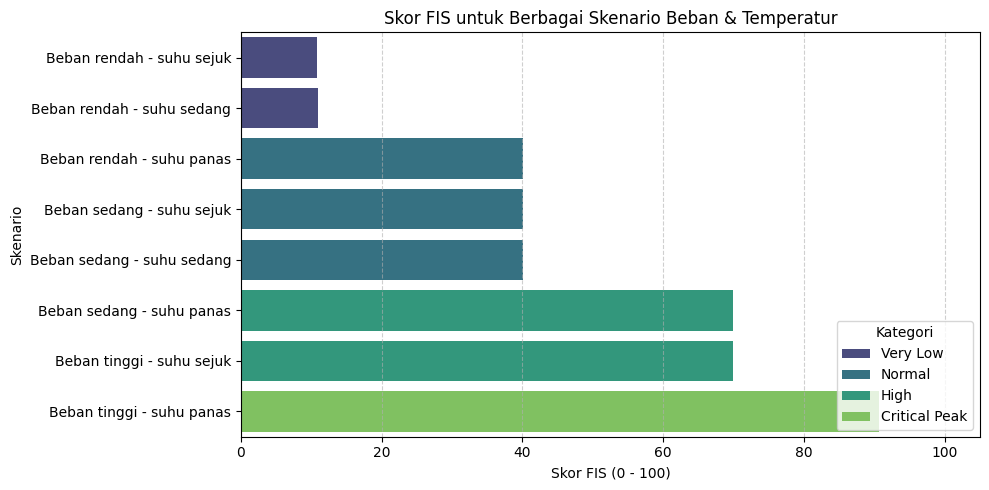

Grafik hasil skenario berhasil disimpan sebagai FIS_hasil_skenario.png


In [ ]:
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.barplot(
    x='Skor FIS',
    y='Skenario',
    hue='Kategori',
    data=df_hasil_skenario,
    palette='viridis',
    dodge=False
)

plt.title('Skor FIS untuk Berbagai Skenario Beban & Temperatur')
plt.xlabel('Skor FIS (0 - 100)')
plt.ylabel('Skenario')
plt.xlim(0, 105)
plt.grid(True, axis='x', linestyle='--', alpha=0.6)
plt.legend(title='Kategori', loc='lower right')
plt.tight_layout()

# Simpan grafik visualisasi skenario
plt.savefig('FIS_hasil_skenario.png', dpi=200, bbox_inches='tight')
plt.show()
print('Grafik hasil skenario berhasil disimpan sebagai FIS_hasil_skenario.png')

## 10. Kesimpulan sementara dan batasan

FIS Mamdani telah dibangun dengan dua variabel input (total beban dan temperatur), tiga himpunan keanggotaan pada setiap input, empat himpunan output, serta sembilan aturan. Skor crisp diperoleh melalui defuzzifikasi centroid dan dikelompokkan menjadi Very Low, Normal, High, atau Critical Peak.

Hasil pada tabel skenario menunjukkan perilaku sistem untuk kombinasi input yang diuji. Interpretasi akhir harus mengacu pada angka yang benar-benar dihasilkan saat notebook dijalankan.

**Batasan yang perlu dicantumkan dalam laporan:**
- Parameter input dihitung dari 70% data awal secara kronologis.
- Pengujian skenario tidak sama dengan validasi seluruh data testing.
- FIS mengubah dua input menjadi skor/kategori; FIS tidak melatih model prediksi.
- Jika suatu saat FIS akan menerima prediksi model lain, kesesuaian satuan, rentang nilai, dan timestamp input harus diperiksa terlebih dahulu. Integrasi tersebut berada di luar cakupan notebook ini.